<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4105_MushroomProject/blob/main/Code/MushroomProject_CreateCSV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/MushroomProject/Mushroom_Dataset.zip"

extract_path = "/content/mushroom_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [3]:
inner_path = os.path.join(extract_path, "mushroom_dataset", "Classes")
print(os.listdir(inner_path))

['poisonous', 'edible', 'deadly', 'conditionally_edible']


In [4]:
for category in os.listdir(inner_path):

    category_path = os.path.join(inner_path, category)

    if os.path.isdir(category_path):

        print("\nCATEGORY:", category)

        species = os.listdir(category_path)

        print("Number of species:", len(species))

        print("First 5 species:", species[:5])


CATEGORY: poisonous
Number of species: 214
First 5 species: ['Amanita_pseudorubescens', 'Imperator_torosus', 'Amanita_flavoconia', 'penny_bun', 'bitter_beech_bolete']

CATEGORY: edible
Number of species: 160
First 5 species: ['Sparassis_crispa', 'Lactarius_deterrimus', 'oyster_mushroom', 'Lentinula_edodes', 'Flammulina_velutipes']

CATEGORY: deadly
Number of species: 40
First 5 species: ['Amanita_subpallidorosea', 'Amanita_bisporigera', 'Tricholoma_equestre', 'Amanita_smithiana', 'Entoloma_sinuatum']

CATEGORY: conditionally_edible
Number of species: 171
First 5 species: ['dusky_puffball', 'Boletus', 'semifree_morel', 'elfin_saddle', 'lilac_fibrecap']


In [5]:
image_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

for category in os.listdir(inner_path):
    category_path = os.path.join(inner_path, category)
    count = 0

    for root, dirs, files in os.walk(category_path):
        count += sum(
            1 for file in files
            if file.lower().endswith(image_extensions)
        )

    print(category, ":", count, "images")

poisonous : 21138 images
edible : 18417 images
deadly : 1190 images
conditionally_edible : 61968 images


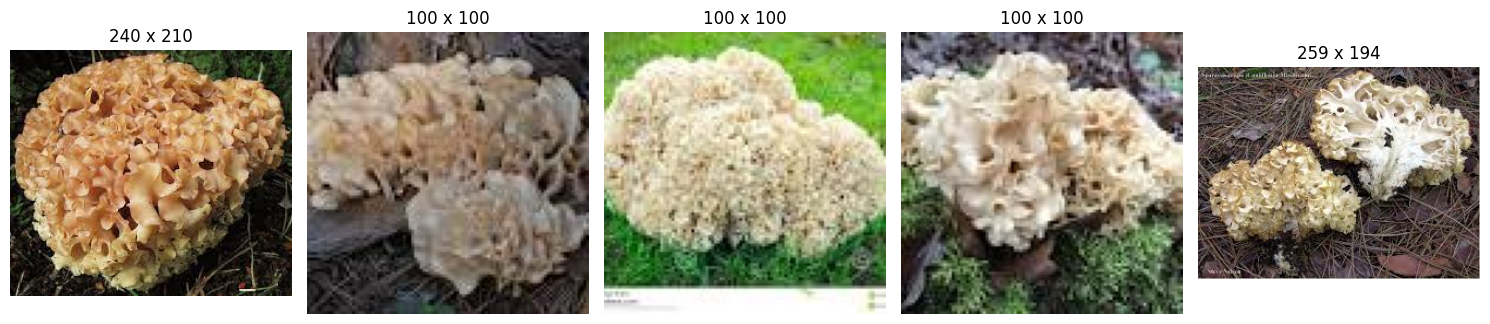

In [6]:
import os
from PIL import Image
import matplotlib.pyplot as plt

edible_path = os.path.join(inner_path, "edible")

image_files = []

for root, dirs, files in os.walk(edible_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')):
            image_files.append(os.path.join(root, file))

# Display the first 5 images
plt.figure(figsize=(15, 6))

for i in range(5):
    img = Image.open(image_files[i])

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{img.width} x {img.height}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
for category in os.listdir(inner_path):
    category_path = os.path.join(inner_path, category)

    if os.path.isdir(category_path):
        copyright_count = 0

        for root, dirs, files in os.walk(category_path):
            for file in files:
                if "copyright-infringement" in file.lower():
                    copyright_count += 1

        print(category, ":", copyright_count, "copyright-flagged images")

poisonous : 1 copyright-flagged images
edible : 0 copyright-flagged images
deadly : 0 copyright-flagged images
conditionally_edible : 6 copyright-flagged images


In [8]:
from PIL import Image
import os

image_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

corrupted_images = []
checked = 0

for root, dirs, files in os.walk(inner_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_path = os.path.join(root, file)

            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted_images.append(image_path)

            checked += 1

print("Images checked:", checked)
print("Corrupted images:", len(corrupted_images))

Images checked: 102713
Corrupted images: 0


In [9]:
from collections import Counter

dimension_counts = Counter()

for root, dirs, files in os.walk(inner_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')):
            image_path = os.path.join(root, file)

            if "copyright-infringement" in file.lower():
                continue

            try:
                with Image.open(image_path) as img:
                    dimension_counts[img.size] += 1
            except Exception:
                pass

print("Number of different image dimensions:", len(dimension_counts))

print("\nMost common dimensions:")
for dimensions, count in dimension_counts.most_common(10):
    print(dimensions, ":", count, "images")

Number of different image dimensions: 2379

Most common dimensions:
(375, 500) : 25469 images
(500, 375) : 17444 images
(500, 333) : 8099 images
(281, 500) : 3245 images
(512, 512) : 3122 images
(100, 100) : 2975 images
(800, 600) : 2900 images
(500, 500) : 2207 images
(500, 281) : 1860 images
(333, 500) : 1641 images


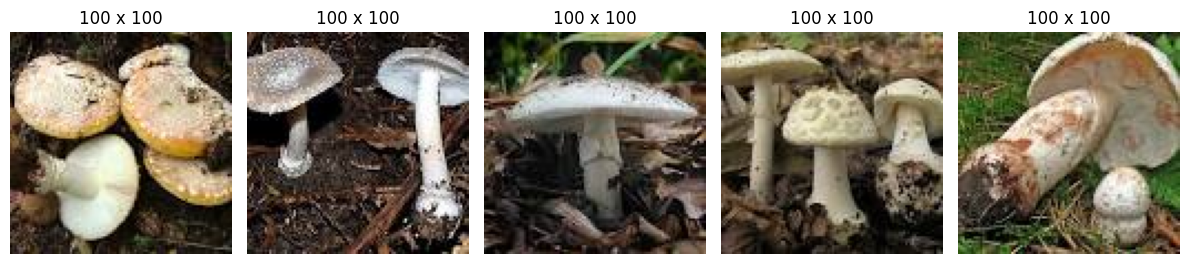

In [10]:
small_images = []

for root, dirs, files in os.walk(inner_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')):
            if "copyright-infringement" in file.lower():
                continue

            image_path = os.path.join(root, file)

            try:
                with Image.open(image_path) as img:
                    if img.size == (100, 100):
                        small_images.append(image_path)
            except Exception:
                pass

plt.figure(figsize=(12, 5))

for i in range(5):
    img = Image.open(small_images[i])

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title("100 x 100")
    plt.axis("off")

plt.tight_layout()
plt.show()

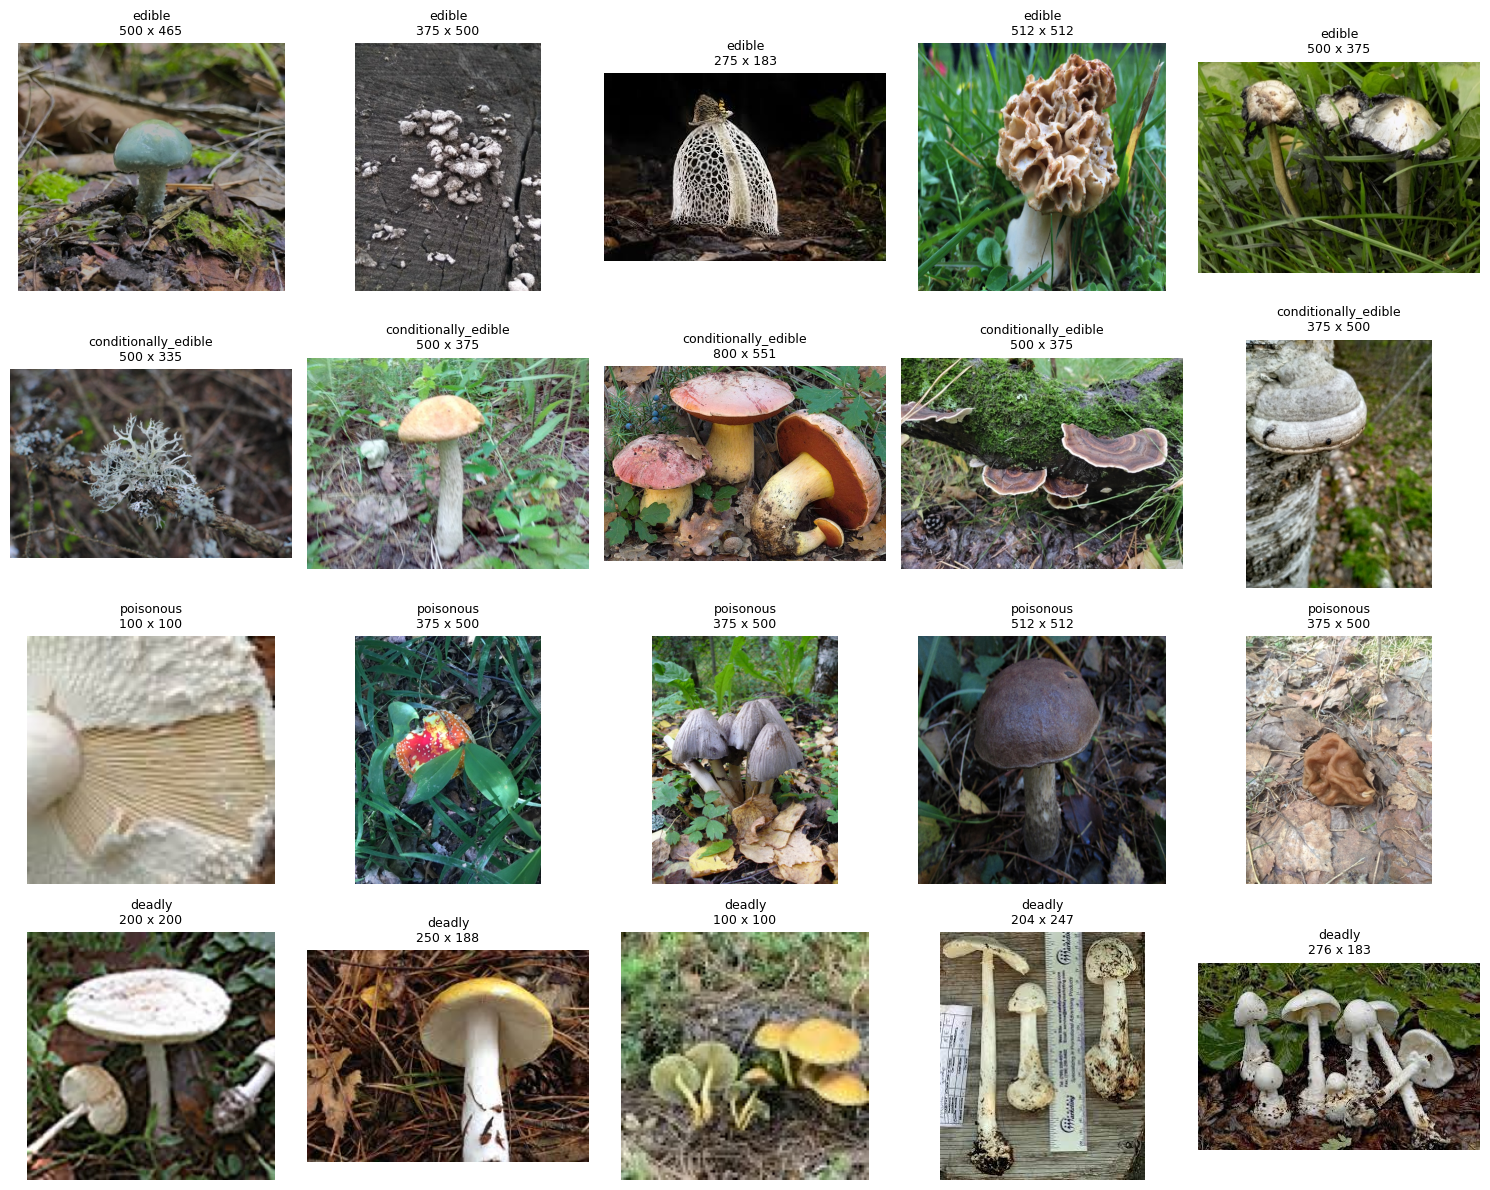

In [11]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

categories = [
    "edible",
    "conditionally_edible",
    "poisonous",
    "deadly"
]

image_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

plt.figure(figsize=(15, 12))

plot_number = 1

for category in categories:
    category_path = os.path.join(inner_path, category)

    image_files = []

    for root, dirs, files in os.walk(category_path):
        for file in files:
            if (file.lower().endswith(image_extensions)
                and "copyright-infringement" not in file.lower()):
                image_files.append(os.path.join(root, file))

    # Select 5 random images
    samples = random.sample(image_files, min(5, len(image_files)))

    for image_path in samples:
        img = Image.open(image_path)

        plt.subplot(4, 5, plot_number)
        plt.imshow(img)
        plt.title(f"{category}\n{img.width} x {img.height}", fontsize=9)
        plt.axis("off")

        plot_number += 1

plt.tight_layout()
plt.show()

In [12]:
for category in categories:
    category_path = os.path.join(inner_path, category)
    count = 0

    for root, dirs, files in os.walk(category_path):
        for file in files:
            if (file.lower().endswith(image_extensions)
                and "copyright-infringement" not in file.lower()):

                image_path = os.path.join(root, file)

                try:
                    with Image.open(image_path) as img:
                        if img.size == (100, 100):
                            count += 1
                except Exception:
                    pass

    print(category, ":", count, "images at 100 x 100")

edible : 884 images at 100 x 100
conditionally_edible : 126 images at 100 x 100
poisonous : 1603 images at 100 x 100
deadly : 362 images at 100 x 100


In [13]:
import os
import pandas as pd

categories = {
    "edible": 1,
    "conditionally_edible": 0,
    "poisonous": 0,
    "deadly": 0
}

image_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

image_data = []

for category, label in categories.items():

    category_path = os.path.join(inner_path, category)

    for root, dirs, files in os.walk(category_path):
        for file in files:

            # Skip copyright-flagged images
            if "copyright-infringement" in file.lower():
                continue

            if file.lower().endswith(image_extensions):

                image_path = os.path.join(root, file)

                image_data.append({
                    "filepath": image_path,
                    "category": category,
                    "label": label
                })

# Create a DataFrame
df = pd.DataFrame(image_data)

print("Total usable images:", len(df))
print("\nImages per category:")
print(df["category"].value_counts())

print("\nBinary label distribution:")
print(df["label"].value_counts().sort_index())

Total usable images: 102706

Images per category:
category
conditionally_edible    61962
poisonous               21137
edible                  18417
deadly                   1190
Name: count, dtype: int64

Binary label distribution:
label
0    84289
1    18417
Name: count, dtype: int64


In [15]:
csv_path = "/content/drive/MyDrive/MushroomProject/mushroom_file_list.csv"

df.to_csv(csv_path, index=False)

print("File list saved successfully!")
print(csv_path)

File list saved successfully!
/content/drive/MyDrive/MushroomProject/mushroom_file_list.csv
